### 1st cell

In [24]:
import os, heapq, itertools, time, warnings
from datetime import date

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import gymnasium as gym
from gymnasium import spaces

from stable_baselines3.common.vec_env import SubprocVecEnv
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback
from sb3_contrib import MaskablePPO
from sb3_contrib.common.wrappers import ActionMasker
from scipy.interpolate import RegularGridInterpolator

### 2nd PDE, grid and exact solution
Burgers: $u_t + a(u)\,u_x = \alpha u_{xx}$ with $a(u)=u$, on $[0,1]$, $u=0$ at both walls, $u(x,0)=\sin\pi x+\tfrac12\sin2\pi x$, $\alpha=0.1$.
Exact solution by Hopf–Cole: $u=-2\alpha\,\phi_x/\phi$, where $\phi$ solves the heat equation with $\phi_x=0$ at the walls (a cosine series).
The exact solution is only used to check results, never by the agent.

inflow_smooth: alpha = 0.1, T = 0.5 | nx = 100, nt = 1099, dx = 0.01010, dt = 4.554e-04 | r = 0.45, nu_max = 0.08, 2r + nu^2 = 0.90
check: FD on a grid 1x finer vs u_true at t = 0.25: max error 5.3e-04
check: FD on a grid 2x finer vs u_true at t = 0.25: max error 1.3e-04
check: FD on a grid 4x finer vs u_true at t = 0.25: max error 3.3e-05


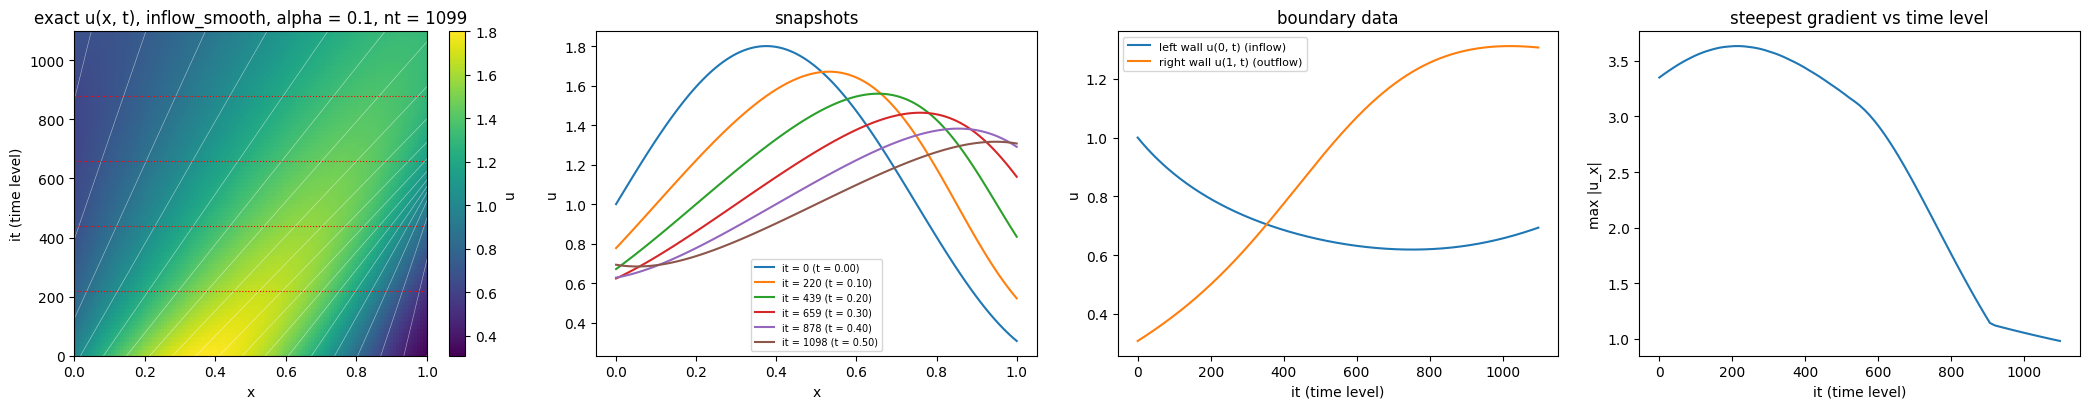

In [25]:
# ── Problem settings: change PROBLEM, everything below follows ──
#   "walls"         : u0 = sin(pi x) + 0.5 sin(2 pi x), u = 0 at both walls, alpha = 0.1   (notebook 12, for comparison)
#   "inflow_smooth" : u0 = 1 + 0.8 sin(2 pi x / 1.5), time-dependent Dirichlet data from the exact solution, alpha = 0.1
#   "inflow_front"  : same, alpha = 0.01: a front forms and leaves (t ~ 0.25-0.35); a second one enters through the left wall (t ~ 0.7)
PROBLEM = "inflow_smooth"
alpha, T = {"walls": (0.1, 0.5), "inflow_smooth": (0.1, 0.5), "inflow_front": (0.01, 1.1)}[PROBLEM]

# ── PDE:  u_t + a(u) u_x = alpha u_xx  on [0, 1] ──
a = lambda u: u                                # advection speed: Burgers
if PROBLEM == "walls":
    u0 = lambda x: np.sin(np.pi * x) + 0.5 * np.sin(2 * np.pi * x)
    F0 = lambda x: (1 - np.cos(np.pi * x)) / np.pi + (1 - np.cos(2 * np.pi * x)) / (4 * np.pi)   # integral of u0 from 0
    A_MAX = 1.5                                # bound on |u| (the IC peaks at about 1.26)
else:
    C_BG, A_W, L_W = 1.0, 0.8, 1.5             # background speed, amplitude, wavelength: u stays in [0.2, 1.8] > 0
    u0 = lambda x: C_BG + A_W * np.sin(2 * np.pi * x / L_W)        # (wavelength != 1, so the two walls see different data)
    F0 = lambda x: C_BG * x + A_W * L_W * (1 - np.cos(2 * np.pi * x / L_W)) / (2 * np.pi)
    A_MAX = C_BG + A_W

# ── Grid ──
# explicit advection + diffusion (LW, FD-3) is stable for 2r + nu^2 <= 1, r = alpha dt/dx^2, nu = A_MAX dt/dx; 0.9 for margin
nx = 100
dx = 1.0 / (nx - 1)
_c2, _c1 = (A_MAX / dx)**2, 2 * alpha / dx**2
nt = int(np.ceil(T / ((-_c1 + np.sqrt(_c1**2 + 4 * _c2 * 0.9)) / (2 * _c2)))) + 1
dt = T / (nt - 1)
x_grid = np.arange(nx) * dx

# ── Exact solution (Hopf-Cole), as a weighted average so it stays accurate for small alpha ──
#    u(x, t) = sum (x - y)/t W / sum W,   W = exp(-F0(y)/(2 alpha) - (x - y)^2 / (4 alpha t)),   y on a uniform grid.
#    "walls": F0 mirrored about every wall (even, period 2) -> phi_x = 0 -> u = 0 at x = 0 and 1.
#    inflow : the whole line, no mirrors; the weight peaks near the foot of the characteristic, y ~ x - u t,
#             so the y range reaches A_MAX * T to the left. Both cover 8 kernel widths. Exponents shifted by their max.
_s = 8 * np.sqrt(2 * alpha * T)
if PROBLEM == "walls":
    _lo, _hi = -np.ceil(_s), 1 + np.ceil(_s)
    _Y  = np.linspace(_lo, _hi, int(round((_hi - _lo) * 10000)) + 1)
    _yf = np.mod(_Y, 2.0)
    _FY = F0(np.where(_yf > 1, 2 - _yf, _yf)) / (2 * alpha)
else:
    _lo, _hi = -A_MAX * T - _s, 1 + _s
    _Y  = np.linspace(_lo, _hi, int(round((_hi - _lo) * 10000)) + 1)
    _FY = F0(_Y) / (2 * alpha)

def u_true(x, t):
    x = np.atleast_1d(np.asarray(x, dtype=float))
    if t <= 0:
        return u0(x)
    out = np.empty(len(x))
    for i in range(0, len(x), 50):                             # chunks of x, to keep memory small
        xs = x[i:i + 50, None]
        E  = -_FY - (xs - _Y)**2 / (4 * alpha * t)
        W  = np.exp(E - E.max(axis=1, keepdims=True))
        out[i:i + 50] = ((xs - _Y) / t * W).sum(1) / W.sum(1)
    return out

# exact values on the grid, one time level at a time when first needed (u_true ONLY for checks, reports, and wall data)
_U_rows = {}
def U_row(it):
    if it not in _U_rows:
        _U_rows[it] = u_true(x_grid, it * dt)
    return _U_rows[it]
Ug = lambda q: U_row(q[1])[q[0]]

# ── Boundary data: u at x = 0 and x = 1 as functions of t (given data, like the IC) ──
# on the grid's time levels it is exact (U_row); between levels (refined classical schemes) a cubic spline through a fine table
from scipy.interpolate import CubicSpline
_tb = np.linspace(0.0, T, 2001)
_gb = np.array([u_true([0.0, 1.0], t) for t in _tb])            # (time, [left, right])
_gs = CubicSpline(_tb, _gb)                                     # cubic in t: accurate enough for high-order schemes too
g_left  = lambda t: float(_gs(t)[0])
g_right = lambda t: float(_gs(t)[1])

r_, nu_ = alpha * dt / dx**2, A_MAX * dt / dx
print(f"{PROBLEM}: alpha = {alpha}, T = {T} | nx = {nx}, nt = {nt}, dx = {dx:.5f}, dt = {dt:.3e} | "
      f"r = {r_:.2f}, nu_max = {nu_:.2f}, 2r + nu^2 = {2 * r_ + nu_**2:.2f}")

# ── Check: an explicit FD solve (with the same boundary data) on finer grids must converge to u_true (error / 4 per halving) ──
def _fd_fine(k, t_end):
    n, h = (nx - 1) * k + 1, dx / k
    steps = int(np.ceil(t_end / min(0.2 * h**2 / alpha, 0.5 * h / A_MAX))); s = t_end / steps
    u = u0(np.arange(n) * h)
    for j in range(steps):
        u[1:-1] = u[1:-1] + alpha * s / h**2 * (u[2:] - 2 * u[1:-1] + u[:-2]) - u[1:-1] * s / (2 * h) * (u[2:] - u[:-2])
        u[0], u[-1] = g_left((j + 1) * s), g_right((j + 1) * s)
    return u[::k]
_t_chk = 0.5 * T
for k in (1, 2, 4):
    print(f"check: FD on a grid {k}x finer vs u_true at t = {_t_chk:.2f}: max error {np.abs(_fd_fine(k, _t_chk) - u_true(x_grid, _t_chk)).max():.1e}")
# ── Pictures: u(x, t) with characteristics, snapshots, boundary data, steepest gradient (time in levels it = t / dt) ──
xf  = np.linspace(0, 1, 121)
its = np.linspace(0, nt - 1, 81).round().astype(int)               # time levels sampled for the pictures
Uxt = np.array([u_true(xf, it * dt) for it in its])
fig, axes = plt.subplots(1, 4, figsize=(21, 4.2))
im = axes[0].pcolormesh(xf, its, Uxt, shading="auto", cmap="viridis")
fig.colorbar(im, ax=axes[0], label="u")
if PROBLEM != "walls":                                              # characteristics x = x_0 + u0(x_0) t (inviscid, until they cross)
    for x_0 in np.linspace(-A_MAX * T, 1, 30):
        axes[0].plot(x_0 + u0(x_0) * its * dt, its, "w-", lw=0.4, alpha=0.6)
snap = np.linspace(0, nt - 1, 6).round().astype(int)                # levels of the snapshots, marked on the map
for it in snap:
    axes[0].axhline(it, color="r", ls=":", lw=0.8)
axes[0].set_xlim(0, 1); axes[0].set_ylim(0, nt - 1)
axes[0].set_xlabel("x"); axes[0].set_ylabel("it (time level)"); axes[0].set_title(f"exact u(x, t), {PROBLEM}, alpha = {alpha}, nt = {nt}")
for it in snap:
    axes[1].plot(xf, u_true(xf, it * dt), label=f"it = {it} (t = {it * dt:.2f})")
axes[1].set_xlabel("x"); axes[1].set_ylabel("u"); axes[1].legend(fontsize=7); axes[1].set_title("snapshots")
axes[2].plot(_tb / dt, _gb[:, 0], label="left wall u(0, t) (inflow)" if PROBLEM != "walls" else "left wall")
axes[2].plot(_tb / dt, _gb[:, 1], label="right wall u(1, t) (outflow)" if PROBLEM != "walls" else "right wall")
axes[2].set_xlabel("it (time level)"); axes[2].set_ylabel("u"); axes[2].legend(fontsize=8); axes[2].set_title("boundary data")
axes[3].plot(its, np.abs(np.gradient(Uxt, xf, axis=1)).max(axis=1))
axes[3].set_xlabel("it (time level)"); axes[3].set_ylabel("max |u_x|"); axes[3].set_title("steepest gradient vs time level")
plt.tight_layout(); plt.show()

### 3rd Cell

**Taylor predictor (thesis §2.5).** The value at a point $p$ is predicted from 5 neighbours $q$: $\hat u_p=\sum_q w_q u_q$.
Each neighbour sits at an offset from $p$: $\Delta x_q = x_q - x_p$ in space and $\Delta t_q = t_q - t_p$ in time ($\Delta t_q<0$, the neighbours are earlier).
Expanding each $u_q$ in a Taylor series about $p$ and replacing $u_t$ by the PDE ($u_t=\alpha u_{xx}-a\,u_x$, with the speed $a$ frozen at its value at $p$), the offsets only appear in the combination
$$\xi_q=\Delta x_q-a\,\Delta t_q ,$$
the neighbour's offset **in a frame moving with the flow** at speed $a$: a point that was carried to $p$ by the flow has $\xi=0$.
The weights then satisfy
$$\sum w=1,\qquad \sum w\,\xi=0,\qquad \sum w\left(\tfrac12\xi^2+\alpha\Delta t\right)=0 ,$$
i.e. the prediction is exact for the constant, the slope and the curvature terms.
We take the min-norm solution. A stencil is **admissible** if the rows have rank 3, cond $\le10^4$ and $\|w\|_1\le2$. The weights can be solved for many stencils at once.
Check: with 3 points one level down, the predictor is exactly Lax–Wendroff, for any local speed $a$.

In [26]:
# ── Taylor predictor: 3 rows (value, u_x, u_xx) with u_t = alpha u_xx - a u_x substituted ──
COND_MAX, W_MAX = 1e4, 2.0
def solve_weights_many(DX, DT, a_loc):
    """Min-norm weights for M stencils at once: DX, DT of shape (M, n) = neighbour offsets, a_loc = local speed.
    Returns W (M, n) and ok (M,): admissible = rank 3, cond <= COND_MAX and ||w||_1 <= W_MAX."""
    xi = DX - a_loc * DT                                              # offset in the moving frame
    h  = np.maximum(np.abs(DX).max(1), np.sqrt(alpha * np.abs(DT).max(1)))[:, None]
    A  = np.stack([np.ones_like(DX), xi / h, (0.5 * xi**2 + alpha * DT) / h**2], axis=1)   # (M, 3, n)
    s  = np.linalg.svd(A, compute_uv=False)                           # singular values, largest first
    ok = (s[:, -1] > s[:, 0] * DX.shape[1] * np.finfo(float).eps) & (s[:, 0] <= COND_MAX * s[:, -1])
    W  = np.linalg.pinv(A) @ np.array([1.0, 0.0, 0.0])
    return W, ok & (np.abs(W).sum(1) <= W_MAX)

def solve_weights(dxs, dts, a_loc):
    """One stencil: weights, or None if not admissible."""
    W, ok = solve_weights_many(dxs[None], dts[None], a_loc)
    return W[0] if ok[0] else None

### Local error estimate (score)
The local error of a stencil at $p$ is $\delta_p=u_p-\sum_q w_q u_q$. Expanding each neighbour value $u_q$ in a Taylor series around $p$ (and using $\sum_q w_q=1$):
$$\delta_p\approx-\sum_q w_q\,P_p(\Delta x_q,\Delta t_q),\qquad s_p=\Big|\sum_q w_q\,P_p(\Delta x_q,\Delta t_q)\Big| ,$$
where $P_p$ is the Taylor polynomial of $u$ around $p$, kept up to weight 4 (a $\Delta t$ counts like two $\Delta x$'s, since $\alpha\Delta t\sim\Delta x^2$):
$$P_p=u_x\Delta x+u_t\Delta t+\tfrac12u_{xx}\Delta x^2+u_{xt}\Delta x\Delta t+\tfrac12u_{tt}\Delta t^2+\tfrac16u_{xxx}\Delta x^3+\tfrac12u_{xxt}\Delta x^2\Delta t+\tfrac1{24}u_{xxxx}\Delta x^4 .$$
Every time derivative is replaced using Burgers ($u_t=\alpha u_{xx}-u\,u_x$), so only the space derivatives $u,u_x,\dots,u_{xxxx}$ at $p$ are needed:

| | |
|---|---|
| $u_t$ | $\alpha u_{xx}-u\,u_x$ |
| $u_{xt}$ | $\alpha u_{xxx}-u\,u_{xx}-u_x^2$ |
| $u_{xxt}$ | $\alpha u_{xxxx}-u\,u_{xxx}-3u_xu_{xx}$ |
| $u_{tt}$ | $\alpha^2u_{xxxx}-2\alpha u\,u_{xxx}+u^2u_{xx}+2u_x(u\,u_x-2\alpha u_{xx})$ |

The terms with $u_x^2$ and $u_xu_{xx}$ come from the nonlinear term: the speed $u$ changes across the stencil. A score built for the linear equation (frozen speed) misses them.
Check: random admissible stencils at random points below $z^*$, with the **exact** derivatives (from the exact solution), score against the true local error.

300 admissible stencils, |u_x| from 0.01 to 3.62
corr(log score, log true error) = 1.00, median |score - true error| / true error = 0.01


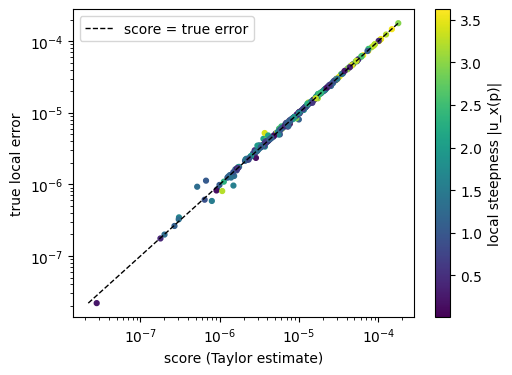

In [27]:
# ── Local error estimate (score): the stencil's error on the local Taylor polynomial of u around p ──
# PDE-specific part: Taylor coefficients with every time derivative replaced using Burgers, u_t = alpha u_xx - u u_x
def taylor_coeffs(d):
    """d = (u, u_x, u_xx, u_xxx, u_xxxx) at p. Returns {(i, j): (d/dx)^i (d/dt)^j u / (i! j!)} for weight i + 2j <= 4."""
    u, u1, u2, u3, u4 = d
    ut   = alpha * u2 - u * u1
    uxt  = alpha * u3 - u * u2 - u1**2                                     # Burgers term: - u_x^2
    uxxt = alpha * u4 - u * u3 - 3 * u1 * u2                               # Burgers term: - 3 u_x u_xx
    utt  = alpha**2 * u4 - 2 * alpha * u * u3 + u**2 * u2 + 2 * u1 * (u * u1 - 2 * alpha * u2)   # Burgers term: 2 u_x (...)
    return {(1, 0): u1, (2, 0): u2 / 2, (3, 0): u3 / 6, (4, 0): u4 / 24,
            (0, 1): ut, (1, 1): uxt, (2, 1): uxxt / 2, (0, 2): utt / 2}

def score(DX, DT, w, d):
    """|sum_q w_q P(dx_q, dt_q)|, P = Taylor polynomial of u around p (without u_p). One stencil (n,) or M stencils (M, n)."""
    P = sum(c * DX**i * DT**j for (i, j), c in taylor_coeffs(d).items())
    return np.abs((w * P).sum(-1))

def x_derivs(f, x, h=2e-3):
    """(u, u_x, u_xx, u_xxx, u_xxxx) of a function f at x, by 7-point central differences."""
    v = f(x + h * np.arange(-3, 4))
    C = [[0, 0, 0, 1, 0, 0, 0], np.array([-1, 9, -45, 0, 45, -9, 1]) / 60, np.array([2, -27, 270, -490, 270, -27, 2]) / 180,
         np.array([1, -8, 13, 0, -13, 8, -1]) / 8, np.array([-1, 12, -39, 56, -39, 12, -1]) / 6]
    return tuple(np.dot(c, v) / h**k for k, c in enumerate(C))

# ── Check: score vs the true local error, for random admissible stencils at random points p anywhere in the domain ──
# here the speed a = u(p) and the derivatives are exact (u_true ONLY for this check); colour = local steepness |u_x|
U = lambda q: u_true(q[0] * dx, q[1] * dt)[0]                       # exact value at one grid point
rng = np.random.default_rng(0)
cells = [(i, j) for j in (-1, -2, -3) for i in range(-3, 4)]               # 3 levels down, |dix| <= 3
S, D, G = [], [], []
while len(S) < 300:
    p = (int(rng.integers(3, nx - 3)), int(rng.integers(3, nt)))          # a random interior point
    nb = [cells[k] for k in rng.choice(len(cells), 5, replace=False)]
    DX, DT = np.array([q[0] for q in nb]) * dx, np.array([q[1] for q in nb]) * dt
    d = x_derivs(lambda x: u_true(x, p[1] * dt), p[0] * dx)
    w = solve_weights(DX, DT, d[0])
    if w is None:
        continue
    u_nb = np.array([U((p[0] + q[0], p[1] + q[1])) for q in nb])
    S.append(score(DX, DT, w, d)); D.append(abs(U(p) - w @ u_nb)); G.append(abs(d[1]))
S, D, G = np.array(S), np.array(D), np.array(G)
print(f"300 admissible stencils, |u_x| from {G.min():.2f} to {G.max():.2f}")
print(f"corr(log score, log true error) = {np.corrcoef(np.log(S), np.log(D))[0, 1]:.2f}, "
      f"median |score - true error| / true error = {np.median(np.abs(S - D) / D):.2f}")

fig, ax = plt.subplots(figsize=(5.5, 4))
sc = ax.scatter(S, D, c=G, s=12, cmap="viridis")
lim = [min(S.min(), D.min()), max(S.max(), D.max())]
ax.loglog(lim, lim, 'k--', lw=1, label='score = true error')
fig.colorbar(sc, label="local steepness |u_x(p)|")
ax.set_xlabel('score (Taylor estimate)'); ax.set_ylabel('true local error'); ax.legend(); plt.show()

### Rough guess of u and its derivatives
To build the map backward, every point needs, before any value has been computed:
- its local speed $a=u$ (for the weights), and
- the space derivatives $u,u_x,\dots,u_{xxxx}$ (for the score, cell 4).

We take them from a cheap **coarse solve**: Lax–Wendroff on a grid 5× coarser, from the initial condition to $T$, computed once for all queries. At each coarse time, a sine series is fitted through the coarse values ($u=0$ at both walls), which gives the derivatives exactly for the fit. In time we interpolate linearly onto our grid.
The guess only steers **which stencils and weights are chosen**. The values at $z^*$ are computed from the neighbours' values, so a poor guess gives worse choices, never wrong numbers. Its cost (840 points) is added to the method's cost.

coarse grid: 20 x 49 = 980 points (dx 0.0526, dt 1.04e-02)
all points   : median relative error for u, u_x, u_xx, u_xxx, u_xxxx: 0.007  0.020  0.030  0.029  0.067
10% steepest : median relative error for u, u_x, u_xx, u_xxx, u_xxxx: 0.005  0.006  0.054  0.042  0.107


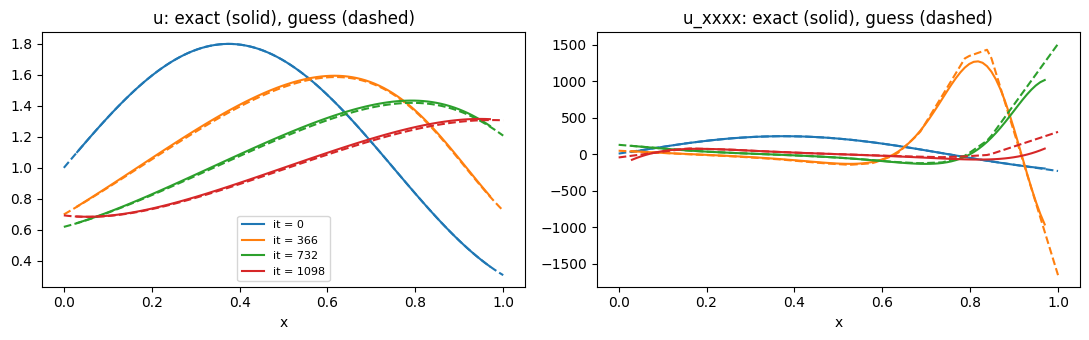

In [28]:
# ── Rough guess of u and its x-derivatives, used ONLY to build the map (speed, weights, score, influence) ──
# Lax-Wendroff on a grid K_COARSE times coarser, from the initial condition to T, with the same boundary data; computed once.
K_COARSE = {"walls": 5, "inflow_smooth": 5, "inflow_front": 2}[PROBLEM]       # the front needs a finer guess
from scipy.interpolate import make_interp_spline
xc  = np.linspace(0.0, 1.0, (nx - 1) // K_COARSE + 1)
hc  = xc[1] - xc[0]
_c2, _c1 = (A_MAX / hc)**2, 2 * alpha / hc**2                                 # same stability rule as the main grid
tau = T / int(np.ceil(T / ((-_c1 + np.sqrt(_c1**2 + 4 * _c2 * 0.9)) / (2 * _c2))))
tc  = np.arange(0.0, T + tau / 2, tau)
Uc  = [u0(xc)]
for j in range(1, len(tc)):
    u, ui = Uc[-1], Uc[-1][1:-1]
    r, nu = alpha * tau / hc**2, a(ui) * tau / hc
    n = u.copy()
    n[1:-1] = ui + (r + nu**2 / 2) * (u[2:] - 2 * ui + u[:-2]) - nu / 2 * (u[2:] - u[:-2])
    n[0], n[-1] = g_left(tc[j]), g_right(tc[j])                               # boundary data
    Uc.append(n)
G_COARSE = len(xc) * len(tc)                                                  # cost of the guess (grid points)

# ── Smooth fit in x at each coarse time: a quintic spline through the coarse values, differentiated exactly ──
Dc = np.zeros((5, len(tc), nx))                                               # (derivative order, coarse time, our x)
for j, u in enumerate(Uc):
    sp = make_interp_spline(xc, u, k=5)
    for k in range(5):
        Dc[k, j] = sp.derivative(k)(x_grid) if k else sp(x_grid)

# ── Linear in time onto our grid: GUESS[k, it, ix] = k-th x-derivative of the guess at grid point (ix, it) ──
tg = np.arange(nt) * dt
jj = np.minimum((tg // tau).astype(int), len(tc) - 2)
f  = ((tg - tc[jj]) / tau)[None, :, None]
GUESS = (1 - f) * Dc[:, jj] + f * Dc[:, jj + 1]
guess_derivs = lambda q: GUESS[:, q[1], q[0]]                                 # (u, u_x, u_xx, u_xxx, u_xxxx) at q

# ── Check: guess vs exact at 300 random points, for all of them and for the 10% steepest (u_true ONLY for this check) ──
print(f"coarse grid: {len(xc)} x {len(tc)} = {G_COARSE} points (dx {hc:.4f}, dt {tau:.2e})")
rng = np.random.default_rng(0)
pts = [(int(rng.integers(3, nx - 3)), int(rng.integers(1, nt))) for _ in range(300)]
ex  = np.array([x_derivs(lambda x: u_true(x, q[1] * dt), q[0] * dx) for q in pts])
gs  = np.array([guess_derivs(q) for q in pts])
rel = np.abs(gs - ex) / (np.abs(ex) + 1e-12)
steep = np.abs(ex[:, 1]) >= np.quantile(np.abs(ex[:, 1]), 0.9)
for name, sel in [("all points", slice(None)), ("10% steepest", steep)]:
    print(f"{name:13s}: median relative error for u, u_x, u_xx, u_xxx, u_xxxx: " + "  ".join(f"{v:.3f}" for v in np.median(rel[sel], axis=0)))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for i, it in enumerate([0, nt // 3, 2 * nt // 3, nt - 1]):
    ex_ = np.array([x_derivs(lambda x: u_true(x, it * dt), xx) for xx in x_grid[3:-3]])
    for ax, k in zip(axes, [0, 4]):
        ax.plot(x_grid[3:-3], ex_[:, k], color=f"C{i}", label=f"it = {it}")
        ax.plot(x_grid, GUESS[k, it], "--", color=f"C{i}")
axes[0].set_title("u: exact (solid), guess (dashed)"); axes[1].set_title("u_xxxx: exact (solid), guess (dashed)")
for ax in axes: ax.set_xlabel("x")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

### Backward map and influence β
**The map.** Start at $z^*$ and give it a stencil. Each neighbour that is not known data (IC or wall) becomes a new point that also needs a stencil. Repeat until every branch ends on the IC or a wall. Points are expanded **latest $t$ first**.

**Weights.** No values exist yet while building, so each point $p$ takes its speed from the guess (cell 5), $a_p=u_{\rm guess}(p)$, rounded to steps of 0.02 so the weights can be cached by (shape, speed). Its score uses the guessed derivatives at $p$ (cell 4).

**Influence.** $\beta_p$ = how much an error at $p$ changes the value at $z^*$. Start with $\beta_{z^*}=1$. When $p$ is expanded with weights $w$, pass its influence down: $\beta_q \mathrel{+}= \beta_p\,w_q$.

**Forward pass.** Values are computed bottom-up from the IC and walls, $\hat u_p=\sum_q w_q\hat u_q$, **with the weights chosen in the map**. Recomputing them with another speed would undo the choice: the score was computed for exactly these weights. The guess shapes the stencils and weights, but no guessed value enters $\hat u$.

**Exact identity.** With $\delta_p=u_p-\sum_q w_qu_q$ the local error,
$$e(z^*)=\sum_p\beta_p\,\delta_p .$$
Check: give every point the Lax–Wendroff stencil; the identity must hold to all digits.

In [29]:
# ── Known data: the initial condition and the walls are given, not computed ──
# their values are the exact solution there: u0 at t = 0, the boundary data g_left / g_right on the walls
is_known    = lambda q: q[1] == 0 or q[0] in (0, nx - 1)
known_value = Ug

# ── Speed at p for its weights: from the guess, rounded to A_STEP so weights can be cached ──
A_STEP  = 0.02
a_build = lambda p: A_STEP * round(a(guess_derivs(p)[0]) / A_STEP)

_w_cache = {}
def weights(p, nbs):
    """Taylor weights of p's neighbours nbs (grid points), with p's guessed speed; None if not admissible.
    Cached by (shape, speed). Solved with the neighbours sorted (latest level first, then left to right), so the
    result never depends on the order the neighbours were picked in."""
    order = sorted(range(len(nbs)), key=lambda i: (-nbs[i][1], nbs[i][0]))
    offs  = tuple((nbs[i][0] - p[0], nbs[i][1] - p[1]) for i in order)
    key   = (offs, a_build(p))
    if key not in _w_cache:
        _w_cache[key] = solve_weights(np.array([o[0] for o in offs]) * dx, np.array([o[1] for o in offs]) * dt, key[1])
    if _w_cache[key] is None:
        return None
    w = np.empty(len(nbs)); w[order] = _w_cache[key]                  # back to the order of nbs
    return w

def point_score(p, nbs, w):
    """Estimated local error of p's stencil, with the guessed derivatives at p."""
    return score(np.array([q[0] - p[0] for q in nbs]) * dx, np.array([q[1] - p[1] for q in nbs]) * dt, w, guess_derivs(p))

# ── The map, built backward from z* ──
# Points wait in `pending` and are expanded LATEST t first: every point that can use p is later
# than p, so it is already expanded and p's influence beta_p is complete when p is expanded.
def start_map(z_star):
    return {"z_star": z_star, "pending": [(-z_star[1], z_star[0])], "beta": {z_star: 1.0}, "stencil": {}}

def next_point(m):
    it, ix = m["pending"][0]
    return (ix, -it)

def expand(m, nbs):
    """Give the next point the stencil nbs and pass its influence down: beta_q += beta_p * w_q."""
    it, ix = heapq.heappop(m["pending"])
    p = (ix, -it)
    w = weights(p, nbs)
    m["stencil"][p] = (nbs, w)
    for q, wq in zip(nbs, w):
        if is_known(q):
            continue                                   # IC or wall: exact, the map stops here
        if q not in m["beta"]:
            m["beta"][q] = 0.0
            heapq.heappush(m["pending"], (-q[1], q[0]))
        m["beta"][q] += m["beta"][p] * wq
    return p, w

def build_map(z_star, choose):
    """Whole map; choose(m, p) returns the neighbours of p."""
    m = start_map(z_star)
    while m["pending"]:
        expand(m, choose(m, next_point(m)))
    return m

# ── Forward pass: values bottom-up, from the IC and walls to z*, with the weights chosen in the map ──
def evaluate(m):
    u_hat = {}
    value = lambda q: known_value(q) if is_known(q) else u_hat[q]
    for p in sorted(m["stencil"], key=lambda p: p[1]):          # increasing t: neighbours are ready
        nbs, w = m["stencil"][p]
        u_hat[p] = sum(wq * value(q) for q, wq in zip(nbs, w))
    return u_hat

# ── Check: every point takes the Lax-Wendroff stencil (3 points one level down) ──
# z* = (20, 40) is close enough to the left wall that its cone reaches it: the wall data is used.
# The identity only holds if the known data (IC and walls) is exact.
lw = lambda m, p: [(p[0] - 1, p[1] - 1), (p[0], p[1] - 1), (p[0] + 1, p[1] - 1)]
z = (20, 40)
m = build_map(z, lw)
err = Ug(z) - evaluate(m)[z]
delta = {p: Ug(p) - w @ np.array([Ug(q) for q in nbs]) for p, (nbs, w) in m["stencil"].items()}
n_wall = sum(1 for p, (nbs, w) in m["stencil"].items() for q in nbs if q[0] in (0, nx - 1) and q[1] > 0)
print(f"LW map at z* = {z}: {len(m['stencil'])} points, {n_wall} uses of wall data | error at z* {abs(err):.2e}")
print(f"identity: e(z*) = {err:.6e}, sum beta*delta = {sum(m['beta'][p] * delta[p] for p in delta):.6e}")

LW map at z* = (20, 40): 1390 points, 20 uses of wall data | error at z* 3.98e-06
identity: e(z*) = -3.979774e-06, sum beta*delta = -3.979774e-06


### Window, admissible stencils and the mask
**Window.** The candidate neighbours of $p$ are the 21 cells up to 3 to each side and 1 to 3 levels below $p$. A cell past a wall or below $t=0$ is moved onto the wall or the IC (known data).
**Admissible stencils.** Every choice of 5 cells whose weights pass the admissibility test (cell 3), with $p$'s guessed speed. Points with the same local situation (distance to walls/IC) and the same guessed speed share one list, computed once and cached together with each stencil's **moments** $\sum_q w_q\Delta x_q^i\Delta t_q^j$. The score at a point is then just these moments times the Taylor coefficients at that point (cell 4): one small product per point.
**Mask.** The agent will pick the 5 cells one at a time. A cell may be picked next only if some admissible stencil contains it together with the picks so far, so the agent can never end up with a bad stencil.
**First rule without RL:** every point takes its lowest-score stencil. **Report** gives a finished map's points, its true error at $z^*$ and its exact bound $\sum_p|\beta_p\delta_p|$ (exact solution used only for reporting).

21 window cells | interior point (50, 40): 18704 admissible stencils of 20349
first pick allowed on 21 cells
LW          : 1600 points, error 1.54e-05, exact bound 1.28e-04  (0 s)
lowest score: 2396 points, error 1.00e-05, exact bound 1.34e-05  (15 s)


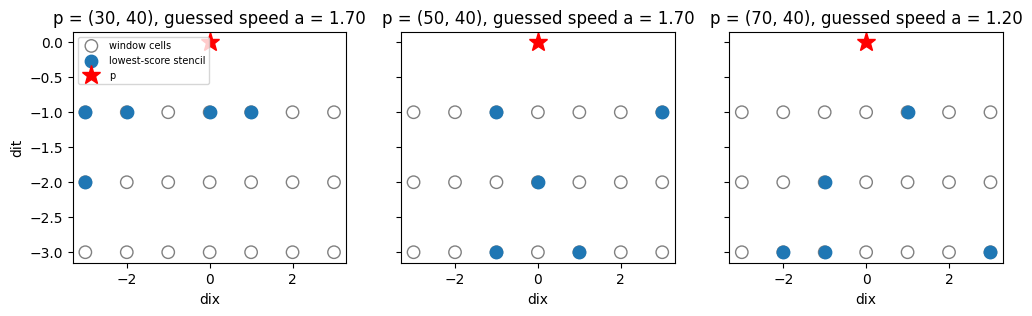

In [30]:
# ── The window: candidate neighbour cells below p ──
R_X, K_T = 3, 3                       # |dix| <= 3 cells, 1 to 3 levels down
WINDOW  = [(dix, dit) for dit in range(-1, -K_T - 1, -1) for dix in range(-R_X, R_X + 1)]
N_CELLS = len(WINDOW)
N_NB    = 5                           # neighbours per stencil
TERMS   = list(taylor_coeffs((0.0,) * 5))                             # the (i, j) Taylor terms of the score

def place(p, k):
    """Grid point of window cell k seen from p. Past a wall or below t = 0 -> moved onto it."""
    return (min(max(p[0] + WINDOW[k][0], 0), nx - 1), max(p[1] + WINDOW[k][1], 0))

# ── Every admissible stencil at p ──
# Cached by p's local situation and guessed speed: the stencils, which cells they use, and their moments
# sum_q w_q dx^i dt^j for each Taylor term. The score at p is then |moments @ Taylor coefficients at p|.
_sets_cache = {}
def admissible(p):
    """(stencils as tuples of cells, cell-usage matrix, scores at p). Cells that land on the same point count once."""
    key = (tuple((place(p, k)[0] - p[0], place(p, k)[1] - p[1]) for k in range(N_CELLS)), a_build(p))
    if key not in _sets_cache:
        cells, seen = [], set()
        for k in range(N_CELLS):
            if place(p, k) not in seen:
                seen.add(place(p, k)); cells.append(k)
        sets = list(itertools.combinations(cells, min(N_NB, len(cells))))
        off  = np.array([[(place(p, k)[0] - p[0], place(p, k)[1] - p[1]) for k in s] for s in sets])   # (M, n, 2)
        DX, DT = off[..., 0] * dx, off[..., 1] * dt
        W, ok  = solve_weights_many(DX, DT, a_build(p))                # all candidate stencils in one solve
        sets   = [s for s, o in zip(sets, ok) if o]
        mom    = np.stack([(W[ok] * DX[ok]**i * DT[ok]**j).sum(1) for i, j in TERMS], axis=1)
        uses   = np.zeros((len(sets), N_CELLS), dtype=bool)
        for i, s in enumerate(sets):
            uses[i, list(s)] = True
        _sets_cache[key] = (sets, uses, mom)
    sets, uses, mom = _sets_cache[key]
    c = taylor_coeffs(guess_derivs(p))
    return sets, uses, np.abs(mom @ np.array([c[t] for t in TERMS]))

def pick_mask(p, picks):
    """Cell k may be picked next if some admissible stencil contains the picks so far plus k."""
    _, uses, _ = admissible(p)
    ok = uses[:, picks].all(axis=1) if picks else np.ones(len(uses), dtype=bool)
    mask = uses[ok].any(axis=0)
    mask[picks] = False
    return mask

# ── A first rule without RL: every point takes its lowest-score stencil ──
def lowest_score(m, p):
    sets, _, sc = admissible(p)
    return [place(p, k) for k in sets[int(np.argmin(sc))]]

# ── Report of a finished map: points, true error at z*, exact bound sum |beta delta| (u_true ONLY for reporting) ──
def report(m):
    z = m["z_star"]
    delta = {p: Ug(p) - w @ np.array([Ug(q) for q in nbs]) for p, (nbs, w) in m["stencil"].items()}
    return {"points": len(m["stencil"]), "error": abs(Ug(z) - evaluate(m)[z]),
            "bound": sum(abs(m["beta"][p] * delta[p]) for p in delta)}

z = (50, 40)
sets, _, sc = admissible(z)
print(f"{N_CELLS} window cells | interior point {z}: {len(sets)} admissible stencils of "
      f"{len(list(itertools.combinations(range(N_CELLS), N_NB)))}")
print("first pick allowed on", pick_mask(z, []).sum(), "cells")

for name, rule in [("LW", lw), ("lowest score", lowest_score)]:
    t0 = time.time()
    rep = report(build_map(z, rule))
    print(f"{name:12s}: {rep['points']} points, error {rep['error']:.2e}, exact bound {rep['bound']:.2e}  ({time.time() - t0:.0f} s)")

# ── Picture: the lowest-score stencil at three points with different speeds ──
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, p in zip(axes, [(30, 40), (50, 40), (70, 40)]):
    sets, _, sc = admissible(p)
    best = sets[int(np.argmin(sc))]
    ax.scatter(*np.array(WINDOW).T, s=80, facecolors='none', edgecolors='gray', label='window cells')
    ax.scatter(*np.array([WINDOW[k] for k in best]).T, s=80, color='tab:blue', label='lowest-score stencil')
    ax.plot(0, 0, 'r*', ms=14, label='p')
    ax.set_title(f"p = {p}, guessed speed a = {a_build(p):.2f}"); ax.set_xlabel('dix')
axes[0].set_ylabel('dit'); axes[0].legend(fontsize=7, loc='upper left'); plt.show()

### Environment
**Episode.** Build one map for the query $z^*$. At each step the agent picks one window cell for the current point (the latest-$t$ pending point). After 5 picks the stencil is complete, the point is expanded (cell 6), and the next point comes up. The episode ends when no points are pending.
**Mask.** Only cells that can still complete an admissible stencil are allowed (cell 7). Points with a single admissible stencil (next to the IC) are played automatically.
**Reward**, given each time a stencil is complete:
$$r_p=-\frac{|\beta_p|\,s_p}{B_{\rm LW}}-\lambda\,\frac{\text{new points}}{N_{\rm LW}},$$
where $s_p$ is the score (cell 4, with the guessed derivatives), and $B_{\rm LW}$, $N_{\rm LW}$ are the score sum and point count of the Lax–Wendroff map of the same $z^*$. So the total return is $-B/B_{\rm LW}-\lambda(N-1)/N_{\rm LW}$, and LW itself scores $\approx -1-\lambda$.
**Cap.** If the map grows past $3N_{\rm LW}$ points, the episode stops, and each point left unexpanded costs its worst stencil.
**State**, for the current point $p$:
- per window cell: already picked, already in the map (reusing it is free), known data (IC/wall), and the best score still reachable through it;
- and globally: $\log|\beta_p|$, levels above the IC, offset to $z^*$, pick number, points used so far, and the pending workload (points still waiting and their total influence).

In [31]:
# ── Units of the reward ──
#   accuracy: the estimated error share |beta_p| s_p, in units of EPS (a fixed target error for the problem, same for every query)
#   cost:     new points, in units of N_LW (the point count of the Lax-Wendroff map of the same z*: "a classical solve")
EPS = {"walls": 1e-5, "inflow_smooth": 1e-5, "inflow_front": 1e-4}[PROBLEM]   # provisional: set from the scan

_nlw_cache = {}
def n_lw(z):
    """Points of the LW map of z* (the cost unit)."""
    if z not in _nlw_cache:
        _nlw_cache[z] = len(build_map(z, lw)["stencil"])
    return _nlw_cache[z]

# ── Environment: one step = one pick; a reward each time a stencil is complete ──
#   reward of a stencil at p:  -|beta_p| s_p / EPS  -  lam * (new points) / N_LW
#   lam (the price of a point) is drawn per episode, log-uniform in lam_range, and shown to the agent
L_SCALE = 0.1                                                     # length scale that makes u_x, u_xx of order 1
N_OBS   = 3 * N_CELLS + 12

class MapEnv(gym.Env):
    def __init__(self, queries, lam_range=(0.1, 10.0), cap=3.0):
        super().__init__()
        self.queries, self.lam_range, self.cap = queries, lam_range, cap
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(N_OBS,), dtype=np.float32)
        self.action_space = spaces.Discrete(N_CELLS)               # one action = one window cell

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.z   = self.queries[self.np_random.integers(len(self.queries))]
        self.lam = float(np.exp(self.np_random.uniform(*np.log(self.lam_range))))
        self.N_ref = n_lw(self.z)
        self.m, self.picks, self.B = start_map(self.z), [], 0.0
        self._play_forced()
        return self._obs(), {}

    def _complete(self, cells):
        """Expand the next point with these cells and return its reward."""
        p = next_point(self.m)
        nbs = [place(p, k) for k in cells]
        n_new = sum(1 for q in set(nbs) if not is_known(q) and q not in self.m["beta"])
        _, w = expand(self.m, nbs)
        term = abs(self.m["beta"][p]) * point_score(p, nbs, w)
        self.B += term
        return -term / EPS - self.lam * n_new / self.N_ref

    def _play_forced(self):
        """Points with only one admissible stencil (e.g. next to the IC) need no decision."""
        r = 0.0
        while self.m["pending"] and len(admissible(next_point(self.m))[0]) == 1:
            r += self._complete(admissible(next_point(self.m))[0][0])
        return r

    def _obs(self):
        if not self.m["pending"]:
            return np.zeros(N_OBS, np.float32)
        p = next_point(self.m)
        pts    = [place(p, k) for k in range(N_CELLS)]
        picked = np.zeros(N_CELLS); picked[self.picks] = 1
        exists = np.array([q in self.m["beta"] for q in pts])            # reusing it creates no new point
        known  = np.array([is_known(q) for q in pts])                    # IC or wall: exact, the branch ends there
        pend   = [(ix, -it) for it, ix in self.m["pending"]]
        d      = guess_derivs(p)
        glob = [np.log10(abs(self.m["beta"][p]) + 1e-12),          # influence of p on z*
                p[1] / self.z[1],                                  # height above the IC, as a fraction of z*'s
                (p[0] - self.z[0]) / nx,                           # offset to z* in x
                p[0] / nx, (nx - 1 - p[0]) / nx,                   # distance to the left and right wall
                d[0], d[1] * L_SCALE, d[2] * L_SCALE**2,           # local solution (guess): speed, slope, curvature
                len(self.m["stencil"]) / self.N_ref,               # points used so far
                len(pend) / self.N_ref,                            # points still waiting for a stencil
                sum(abs(self.m["beta"][q]) for q in pend),         # their total influence
                np.log10(self.lam)]                                # price of a point
        return np.concatenate([picked, exists, known, glob]).astype(np.float32)

    def step(self, k):
        self.picks.append(int(k))
        p = next_point(self.m)
        if len(self.picks) < len(admissible(p)[0][0]):             # still choosing p's stencil
            return self._obs(), 0.0, False, False, {}
        r = self._complete(self.picks)
        self.picks = []
        r += self._play_forced()
        n = len(self.m["stencil"]) + len(self.m["pending"])
        if self.m["pending"] and n <= self.cap * self.N_ref:       # map not finished
            return self._obs(), r, False, False, {}
        # finished, or over the point cap: each point left unexpanded costs its worst admissible stencil
        for it, ix in self.m["pending"]:
            q = (ix, -it)
            r -= abs(self.m["beta"][q]) * admissible(q)[2].max() / EPS
        info = {"finished": not self.m["pending"], "points": len(self.m["stencil"]), "lam": self.lam,
                "score_ratio": self.B / EPS, "points_ratio": len(self.m["stencil"]) / self.N_ref}
        return np.zeros(N_OBS, np.float32), r, True, False, info

    def action_masks(self):
        return pick_mask(next_point(self.m), self.picks)

# ── Check: one episode with random (masked) picks; the rewards must add up to the return formula ──
env = MapEnv(queries=[(50, 40)])
obs, _ = env.reset(seed=0)
rng, total, steps, done = np.random.default_rng(0), 0.0, 0, False
while not done:
    obs, r, done, _, info = env.step(rng.choice(np.flatnonzero(env.action_masks())))
    total += r; steps += 1
print(f"obs size {N_OBS} | lam = {info['lam']:.2f} | {steps} picks | finished: {info['finished']} | "
      f"{info['points']} points ({info['points_ratio']:.2f}x LW) | score sum {info['score_ratio']:.1f} EPS")
print(f"sum of rewards {total:.3f}   check: -B/EPS - lam*(points-1)/N_LW = "
      f"{-info['score_ratio'] - info['lam'] * (info['points'] - 1) / env.N_ref:.3f}")

obs size 75 | lam = 1.88 | 12285 picks | finished: True | 2459 points (1.54x LW) | score sum 20.4 EPS
sum of rewards -23.237   check: -B/EPS - lam*(points-1)/N_LW = -23.237


### Map figure
One figure for any finished map, used for the baselines and the training videos:
1. the map, coloured by influence $|\beta_p|$ on $z^*$;
2. a zoom on $z^*$ with the stencils of the top levels;
3. the accumulated error $|\hat u_p-u_p|$ at every computed point;
4. the error share $|\beta_p\delta_p|$ of every point (these add up to the exact bound).

Panels 3 and 4 use the exact solution, only for this figure.

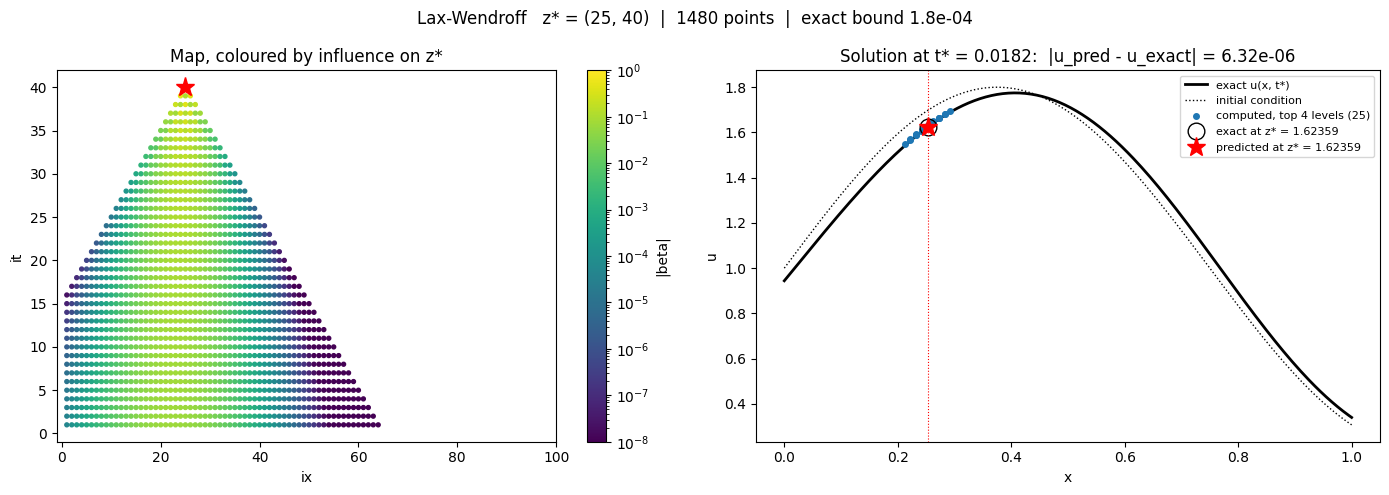

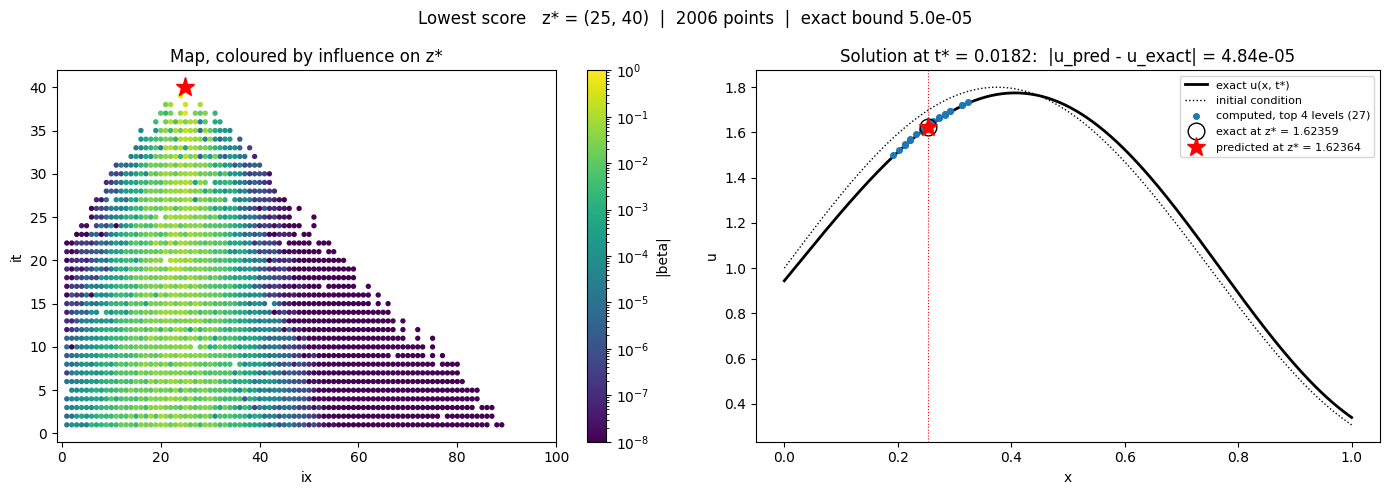

In [32]:
# ── One figure for any finished map (used for the baselines and the training videos) ──
#   left : the map, coloured by influence |beta| on z*
#   right: the solution at t*: exact u(x, t*), the computed points of the top levels, and the value at z* (u_true ONLY here)
from matplotlib.colors import LogNorm

def plot_map(m, title="", path=None, top=4):
    z, rep = m["z_star"], report(m)
    u_hat = evaluate(m)
    P = np.array(list(m["stencil"]))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))

    sc = a1.scatter(P[:, 0], P[:, 1], c=[abs(m["beta"][tuple(p)]) for p in P], s=8, cmap="viridis", norm=LogNorm(1e-8, 1))
    a1.plot(*z, "r*", ms=14)
    fig.colorbar(sc, ax=a1, label="|beta|")
    a1.set_xlim(-1, nx); a1.set_xlabel("ix"); a1.set_ylabel("it"); a1.set_title("Map, coloured by influence on z*")

    xf = np.linspace(0, 1, 201)
    a2.plot(xf, u_true(xf, z[1] * dt), "k-", lw=2, label="exact u(x, t*)")
    a2.plot(xf, u0(xf), "k:", lw=1, label="initial condition")
    near = [p for p in u_hat if p[1] >= z[1] - top]
    a2.plot([p[0] * dx for p in near], [u_hat[p] for p in near], "o", color="C0", ms=4,
            label=f"computed, top {top} levels ({len(near)})")
    a2.plot(z[0] * dx, Ug(z), "ko", ms=12, mfc="none", label=f"exact at z* = {Ug(z):.5f}")
    a2.plot(z[0] * dx, u_hat[z], "r*", ms=14, label=f"predicted at z* = {u_hat[z]:.5f}")
    a2.axvline(z[0] * dx, color="r", ls=":", lw=0.8)
    a2.set_xlabel("x"); a2.set_ylabel("u"); a2.legend(fontsize=8)
    a2.set_title(f"Solution at t* = {z[1] * dt:.4f}:  |u_pred - u_exact| = {rep['error']:.2e}")

    fig.suptitle(f"{title}   z* = {z}  |  {rep['points']} points  |  exact bound {rep['bound']:.1e}")
    plt.tight_layout()
    if path:
        fig.savefig(path, dpi=100, bbox_inches="tight"); plt.close(fig)
    else:
        plt.show()

plot_map(build_map((25 , 40), lw), "Lax-Wendroff")
plot_map(build_map((25, 40), lowest_score), "Lowest score")

### Training helpers and callbacks
- `make_env`: one training environment (with the action mask and the episode monitor).
- `run_policy`: one episode where the policy takes its most likely pick every time; returns the finished map.
- `MapLogCallback`: logs points, score sum (both relative to LW) and the finish rate of the training episodes to TensorBoard.
- `SnapshotCallback`: every `every` steps, runs the current policy on one query, saves its map figure (cell 9) and keeps its numbers. These images become the training-progress video.

All take an environment class (`env_cls`), so the same helpers serve the multi-query environment later.
Check: a tiny run (2 environments, 2048 steps) to see that everything connects.

In [33]:
# ── Helpers for training: environment factory and one deterministic run of a trained policy ──
def make_env(queries, lam_range, seed, env_cls=MapEnv):
    def _init():
        env = Monitor(ActionMasker(env_cls(queries=queries, lam_range=lam_range), lambda e: e.action_masks()))
        env.reset(seed=seed)
        return env
    return _init

def run_policy(model, z, lam, env_cls=MapEnv):
    """One episode on z* at a fixed lam, with the policy's most likely picks. Returns the finished env (map in env.m)."""
    env = env_cls(queries=[z], lam_range=(lam, lam))
    obs, _ = env.reset(seed=0)
    done, ret = False, 0.0
    while not done:
        a, _ = model.predict(obs, action_masks=env.action_masks(), deterministic=True)
        obs, r, done, _, info = env.step(a)
        ret += r
    env.ret, env.info = ret, info
    return env

# ── Callback 1: log map numbers of every finished training episode (mean of the last 100) ──
class MapLogCallback(BaseCallback):
    def __init__(self):
        super().__init__()
        self.hist = {"points_ratio": [], "score_ratio": [], "finished": []}

    def _on_step(self):
        for info in self.locals["infos"]:
            if "points_ratio" in info:                              # only at the end of an episode
                for k in self.hist:
                    self.hist[k].append(float(info[k]))
        for k, v in self.hist.items():
            if v:
                self.logger.record(f"map/{k}", np.mean(v[-100:]))
        return True

# ── Callback 2: every `every` steps, run the current policy on z_plot at a fixed lam, save the figure and the numbers ──
class SnapshotCallback(BaseCallback):
    def __init__(self, z_plot, lam, every, img_dir, env_cls=MapEnv):
        super().__init__()
        self.z_plot, self.lam, self.every, self.img_dir, self.env_cls = z_plot, lam, every, img_dir, env_cls
        self.last, self.hist, self.episodes = -every, [], 0

    def _on_step(self):
        self.episodes += sum("episode" in info for info in self.locals["infos"])   # maps finished in training
        if self.num_timesteps - self.last >= self.every:
            self.last = self.num_timesteps
            env = run_policy(self.model, self.z_plot, self.lam, self.env_cls)
            if env.info["finished"]:
                rep = report(env.m)
                plot_map(env.m, f"step {self.num_timesteps:,}  ({self.episodes} maps)  |  lam {self.lam:g}  |  return {env.ret:.2f}",
                         os.path.join(self.img_dir, f"map_{self.num_timesteps:09d}.png"))
            else:
                rep = {"points": env.info["points"], "error": np.nan, "bound": np.nan}
            self.hist.append({"step": self.num_timesteps, "episodes": self.episodes, "return": env.ret, **rep})
            print(f"step {self.num_timesteps:>10,} | {self.episodes:5d} maps: return {env.ret:7.2f} | "
                  f"{rep['points']} points | bound {rep['bound']:.1e} | finished {env.info['finished']}")
        return True

### Training
MaskablePPO with $\gamma=1$ and `gae_lambda=1.0`: each pick is judged by the actual return of the rest of the episode.
Everything a run produces goes into one folder:
`runs{month}-{day}/{run_name}/config.json` (all settings, including the guess and the score), and for each seed: `images/` (snapshot figures + final map), `checkpoints/` (models), `logs/` (TensorBoard), `snapshots.json` (return, points, error, bound at every snapshot).
The stencil cache is not copied to the 12 workers (about 125 MB each); every worker fills its own in about 25 s.

In [37]:
import json
from stable_baselines3.common.callbacks import CheckpointCallback

# ── Physics check: does the map lean along the characteristic? ──
# for every point: the stencil's mean x-offset vs (guessed speed) x (mean time offset); a slope of 1 = centred on the
# foot of the characteristic, 0 = no lean (symmetric). Least-squares slope through the origin.
def skew_slope(m):
    xs, ys = [], []
    for p, (nbs, w) in m["stencil"].items():
        ys.append(np.mean([q[0] - p[0] for q in nbs]) * dx)
        xs.append(a_build(p) * np.mean([q[1] - p[1] for q in nbs]) * dt)
    xs, ys = np.array(xs), np.array(ys)
    return float((xs * ys).sum() / (xs * xs).sum())
Z_TRAIN = (50, 30)
# ── Training settings: one query, from scratch, lam drawn per episode ──
QUERIES   = [Z_TRAIN]           # training query z* (from the scan cell)
LAM_RANGE = (1.0, 1.0)         # lam drawn log-uniform per episode (from the scan: balance at lam ~ 1)
LAM_PLOT  = 1.0                 # lam used for the snapshots and the final map
SEED      = 1
TOTAL     = 20_000_000           # environment steps (= picks)
N_ENVS    = 12
SNAP_EVERY, CKPT_EVERY = 250_000, 1_000_000
PPO_KW    = dict(n_steps=1024, batch_size=1024, gamma=1.0, gae_lambda=0.97, learning_rate=3e-4, ent_coef=0.0)

# ── Run folder: everything this run produces goes here ──
run_name = f"{PROBLEM}_scratch_gae{PPO_KW['gae_lambda']}_z{Z_TRAIN[0]}-{Z_TRAIN[1]}_lam{LAM_RANGE[0]:g}-{LAM_RANGE[1]:g}"
run_dir  = os.path.join(f"runs{date.today().month}-{date.today().day}", run_name)
img_dir, ckpt_dir = os.path.join(run_dir, "images"), os.path.join(run_dir, "checkpoints")
os.makedirs(img_dir, exist_ok=True); os.makedirs(ckpt_dir, exist_ok=True)
with open(os.path.join(run_dir, "config.json"), "w") as f:
    json.dump(dict(problem=PROBLEM, alpha=alpha, T=T, nx=nx, nt=nt, queries=QUERIES, lam_range=LAM_RANGE, eps=EPS,
                   seed=SEED, total=TOTAL, n_envs=N_ENVS, ppo=PPO_KW, K_COARSE=K_COARSE, N_OBS=N_OBS,
                   window=dict(R_X=R_X, K_T=K_T, N_NB=N_NB), date=str(date.today())), f, indent=2)
print("run folder:", run_dir)

# ── Train ──
for z in QUERIES:
    n_lw(z)                                                     # small: fill before the workers start
_sets_cache.clear(); _w_cache.clear()                           # big: every worker fills its own
vec = SubprocVecEnv([make_env(QUERIES, LAM_RANGE, seed=100 * SEED + i) for i in range(N_ENVS)])
model = MaskablePPO("MlpPolicy", vec, seed=SEED, verbose=0, device="cpu",
                    tensorboard_log=os.path.join(run_dir, "logs"), **PPO_KW)
snap_cb = SnapshotCallback(Z_TRAIN, LAM_PLOT, every=SNAP_EVERY, img_dir=img_dir)
t0 = time.time()
model.learn(total_timesteps=TOTAL, tb_log_name="ppo",
            callback=[MapLogCallback(), snap_cb,
                      CheckpointCallback(save_freq=max(CKPT_EVERY // N_ENVS, 1), save_path=ckpt_dir, name_prefix="ppo")])
vec.close()
print(f"training time: {(time.time() - t0) / 60:.0f} min")

# ── Save, and compare the final policy with the rules at LAM_PLOT ──
model.save(os.path.join(ckpt_dir, "ppo_final"))
with open(os.path.join(run_dir, "snapshots.json"), "w") as f:
    json.dump(snap_cb.hist, f, indent=1, default=float)
env = run_policy(model, Z_TRAIN, LAM_PLOT)
plot_map(env.m, f"final  |  lam {LAM_PLOT:g}  |  return {env.ret:.2f}", os.path.join(img_dir, "map_final.png"))
map_return = lambda mm: -score_sum(mm) / EPS - LAM_PLOT * (len(mm["stencil"]) - 1) / n_lw(Z_TRAIN)
print(f"\nat lam = {LAM_PLOT:g}:")
for name, mm in [("agent", env.m), ("LW", build_map(Z_TRAIN, lw)), ("lowest score", build_map(Z_TRAIN, lowest_score)),
                 ("greedy", build_map(Z_TRAIN, greedy_rule(LAM_PLOT)))]:
    rep = report(mm)
    print(f"{name:>13s}: return {map_return(mm):8.2f} | {rep['points']:5d} points | true bound {rep['bound']:.1e} | "
          f"error {rep['error']:.1e} | skew slope {skew_slope(mm):.2f}")

run folder: runs10-14\inflow_smooth_scratch_gae0.97_z50-30_lam1-1
step         12 |     0 maps: return  -31.31 | 1547 points | bound 3.0e-04 | finished True
step    250,020 |    28 maps: return  -14.15 | 1319 points | bound 1.3e-04 | finished True
step    500,028 |    61 maps: return  -10.78 | 1164 points | bound 9.6e-05 | finished True
step    750,036 |    97 maps: return  -10.96 | 1244 points | bound 9.5e-05 | finished True
step  1,000,044 |   131 maps: return  -11.56 | 1646 points | bound 9.7e-05 | finished True
step  1,250,052 |   160 maps: return  -11.49 | 1567 points | bound 9.7e-05 | finished True
step  1,500,060 |   194 maps: return  -11.41 | 1553 points | bound 9.6e-05 | finished True
step  1,750,068 |   226 maps: return  -11.67 | 1753 points | bound 9.7e-05 | finished True
step  2,000,076 |   255 maps: return  -11.01 | 1616 points | bound 9.2e-05 | finished True
step  2,250,084 |   288 maps: return  -10.96 | 1477 points | bound 9.3e-05 | finished True
step  2,500,092 |   323 

In [14]:
def greedy_rule(lam):
    """At every point the stencil with the best one-step reward."""
    def choose(m, p):
        sets, uses, sc = admissible(p)
        new = np.array([not is_known(place(p, k)) and place(p, k) not in m["beta"] for k in range(N_CELLS)])
        cost = abs(m["beta"][p]) * sc / EPS + lam * (uses.astype(float) @ new) / n_lw(m["z_star"])
        return [place(p, k) for k in sets[int(np.argmin(cost))]]
    return choose                                   # <- this line must be at this indentation (outside choose)

print(greedy_rule(1.0))                             # should print <function greedy_rule.<locals>.choose ...>, not None

<function greedy_rule.<locals>.choose at 0x0000018307B76D40>


In [19]:
# ── Self-contained: the rules this cell needs (overrides any earlier, broken copies) ──
def score_sum(m):
    """B = sum |beta_p| s_p: the map's estimated error bound."""
    return sum(abs(m["beta"][p]) * point_score(p, *m["stencil"][p]) for p in m["stencil"])

def greedy_rule(lam):
    """At every point the stencil with the best one-step reward."""
    def choose(m, p):
        sets, uses, sc = admissible(p)
        new = np.array([not is_known(place(p, k)) and place(p, k) not in m["beta"] for k in range(N_CELLS)])
        cost = abs(m["beta"][p]) * sc / EPS + lam * (uses.astype(float) @ new) / n_lw(m["z_star"])
        return [place(p, k) for k in sets[int(np.argmin(cost))]]
    return choose

assert callable(greedy_rule(1.0)), "greedy_rule is broken"
print(f"EPS = {EPS:.0e}, Z_TRAIN = {Z_TRAIN}")      # should be 1e-05 and (50, 30), the values used in the scratch runs
def skew_slope(m):
    """Lean along the characteristic: slope of the stencil's mean x-offset vs speed x mean time offset (1 = on it, 0 = none)."""
    xs, ys = [], []
    for p, (nbs, w) in m["stencil"].items():
        ys.append(np.mean([q[0] - p[0] for q in nbs]) * dx)
        xs.append(a_build(p) * np.mean([q[1] - p[1] for q in nbs]) * dt)
    xs, ys = np.array(xs), np.array(ys)
    return float((xs * ys).sum() / (xs * xs).sum())

EPS = 1e-05, Z_TRAIN = (50, 30)


In [20]:
# ══ Everything-in run: richer state + imitation of greedy (DAgger) + PPO fine-tuning from the clone ══
#   1) state + u_xxx, u_xxxx (the terms that decide which stencils really cancel)
#   2) imitation: copy greedy's picks; DAgger rounds label the clone's own states with greedy's choice
#   3) the value network is trained on the same rollouts (returns-to-go), so PPO does not start with a random critic
#   4) PPO fine-tuning: gae_lambda 0.95, small learning rate and clip range, to improve on the clone without wrecking it
import json, torch
from stable_baselines3.common.callbacks import CheckpointCallback

LAM       = 1.0                 # fixed price of a point (as in the scratch runs)
QUERIES   = [Z_TRAIN]
DAGGER    = [(1.0, 3), (0.5, 3), (0.25, 3), (0.0, 3)]   # (probability of following greedy, episodes) per round
TOTAL     = 3_000_000           # PPO fine-tuning steps
N_ENVS    = 12
SNAP_EVERY, CKPT_EVERY = 250_000, 1_000_000
PPO_KW    = dict(n_steps=1024, batch_size=1024, n_epochs=5, gamma=1.0, gae_lambda=0.95,
                 learning_rate=1e-4, clip_range=0.1, ent_coef=0.0)

# ── 1) richer state ──
N_OBS_X = N_OBS + 2
class MapEnvX(MapEnv):
    def __init__(self, queries, lam_range=(1.0, 1.0), cap=3.0):
        super().__init__(queries, lam_range, cap)
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(N_OBS_X,), dtype=np.float32)
    def _obs(self):
        if not self.m["pending"]:
            return np.zeros(N_OBS_X, np.float32)
        d = guess_derivs(next_point(self.m))
        return np.concatenate([super()._obs(), [d[3] * L_SCALE**3, d[4] * L_SCALE**4]]).astype(np.float32)
    def step(self, k):
        obs, r, done, trunc, info = super().step(k)
        return (np.zeros(N_OBS_X, np.float32) if done else obs), r, done, trunc, info

# ── 2) greedy's next pick in any state: the best stencil that still contains the picks so far, its first unpicked cell ──
def greedy_pick(env):
    p = next_point(env.m)
    sets, uses, sc = admissible(p)
    ok = uses[:, env.picks].all(axis=1) if env.picks else np.ones(len(sets), dtype=bool)
    new = np.array([not is_known(place(p, k)) and place(p, k) not in env.m["beta"] for k in range(N_CELLS)])
    cost = abs(env.m["beta"][p]) * sc / EPS + env.lam * (uses.astype(float) @ new) / env.N_ref
    cost[~ok] = np.inf
    return min(k for k in sets[int(np.argmin(cost))] if k not in env.picks)

def collect(model, p_expert, n_episodes, rng):
    """Roll out (greedy with probability p_expert, else the model); label every state with greedy's pick."""
    O, Y, M, R = [], [], [], []
    for _ in range(n_episodes):
        env = MapEnvX(QUERIES, (LAM, LAM)); obs, _ = env.reset(seed=int(rng.integers(1_000_000)))
        rews, done = [], False
        while not done:
            mask, y = env.action_masks(), greedy_pick(env)
            O.append(obs); Y.append(y); M.append(mask)
            a = y if rng.random() < p_expert else int(model.predict(obs, action_masks=mask, deterministic=False)[0])
            obs, r, done, _, _ = env.step(a); rews.append(r)
        R.extend(np.cumsum(rews[::-1])[::-1])                    # return-to-go from each state
    return O, Y, M, R

def bc_train(model, O, Y, M, R, epochs=30, batch=512, lr=1e-3):
    """Supervised: maximise log-prob of greedy's picks (masked), and fit the value net to the returns-to-go."""
    O, Y, M, R = np.array(O, np.float32), np.array(Y), np.array(M), np.array(R, np.float32)
    opt, r_var = torch.optim.Adam(model.policy.parameters(), lr=lr), R.var() + 1e-8
    for _ in range(epochs):
        for b in np.array_split(np.random.permutation(len(O)), max(len(O) // batch, 1)):
            values, logp, _ = model.policy.evaluate_actions(torch.as_tensor(O[b]), torch.as_tensor(Y[b]), action_masks=M[b])
            loss = -logp.mean() + 0.5 * ((values.flatten() - torch.as_tensor(R[b]))**2).mean() / r_var
            opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        _, logp, _ = model.policy.evaluate_actions(torch.as_tensor(O), torch.as_tensor(Y), action_masks=M)
    return float(np.exp(logp.numpy()).mean())                  # mean probability given to greedy's pick

def evaluate_policy(model):
    env = run_policy(model, Z_TRAIN, LAM, MapEnvX)
    rep = report(env.m)
    return env, f"return {env.ret:7.2f} | {rep['points']:5d} points | bound {rep['bound']:.1e} | skew {skew_slope(env.m):.2f}"

# ── Run folder ──
run_name = f"{PROBLEM}_imitation_z{Z_TRAIN[0]}-{Z_TRAIN[1]}_lam{LAM:g}"
run_dir  = os.path.join(f"runs{date.today().month}-{date.today().day}", run_name)
img_dir, ckpt_dir = os.path.join(run_dir, "images"), os.path.join(run_dir, "checkpoints")
os.makedirs(img_dir, exist_ok=True); os.makedirs(ckpt_dir, exist_ok=True)
with open(os.path.join(run_dir, "config.json"), "w") as f:
    json.dump(dict(problem=PROBLEM, queries=QUERIES, lam_range=(LAM, LAM), eps=EPS, K_COARSE=K_COARSE, N_OBS=N_OBS_X,
                   dagger=DAGGER, total=TOTAL, ppo=PPO_KW, date=str(date.today())), f, indent=2)
print("run folder:", run_dir)

# ── The reference: greedy's own map ──
mg = build_map(Z_TRAIN, greedy_rule(LAM)); rg = report(mg)
print(f"greedy   : return {-score_sum(mg) / EPS - LAM * (rg['points'] - 1) / n_lw(Z_TRAIN):7.2f} | {rg['points']:5d} points | "
      f"bound {rg['bound']:.1e} | skew {skew_slope(mg):.2f}")

# ── Model (workers start now; the imitation runs in this process) ──
for z in QUERIES:
    n_lw(z)
_sets_cache.clear(); _w_cache.clear()
vec = SubprocVecEnv([make_env(QUERIES, (LAM, LAM), seed=100 + i, env_cls=MapEnvX) for i in range(N_ENVS)])
model = MaskablePPO("MlpPolicy", vec, seed=1, verbose=0, device="cpu", tensorboard_log=os.path.join(run_dir, "logs"), **PPO_KW)

# ── 2-3) Imitation with DAgger ──
rng, data, t0 = np.random.default_rng(0), ([], [], [], []), time.time()
for rnd, (p_expert, n_ep) in enumerate(DAGGER):
    for store, new in zip(data, collect(model, p_expert, n_ep, rng)):
        store.extend(new)
    agree = bc_train(model, *data)
    _, line = evaluate_policy(model)
    print(f"DAgger round {rnd} (greedy prob {p_expert}): {len(data[0])} labelled states, P(greedy's pick) {agree:.2f} | "
          f"clone: {line}  ({(time.time() - t0) / 60:.0f} min)")
model.save(os.path.join(ckpt_dir, "clone"))
env, _ = evaluate_policy(model)
plot_map(env.m, f"clone after imitation  |  lam {LAM:g}  |  return {env.ret:.2f}", os.path.join(img_dir, "map_clone.png"))

# ── 4) PPO fine-tuning from the clone ──
snap_cb = SnapshotCallback(Z_TRAIN, LAM, every=SNAP_EVERY, img_dir=img_dir, env_cls=MapEnvX)
t0 = time.time()
model.learn(total_timesteps=TOTAL, tb_log_name="ppo",
            callback=[MapLogCallback(), snap_cb,
                      CheckpointCallback(save_freq=max(CKPT_EVERY // N_ENVS, 1), save_path=ckpt_dir, name_prefix="ppo")])
vec.close()
print(f"fine-tuning time: {(time.time() - t0) / 60:.0f} min")
model.save(os.path.join(ckpt_dir, "ppo_final"))
with open(os.path.join(run_dir, "snapshots.json"), "w") as f:
    json.dump(snap_cb.hist, f, indent=1, default=float)
env, line = evaluate_policy(model)
plot_map(env.m, f"final  |  lam {LAM:g}  |  return {env.ret:.2f}", os.path.join(img_dir, "map_final.png"))
print(f"final    : {line}")

run folder: runs10-14\inflow_smooth_imitation_z50-30_lam1
greedy   : return   -0.71 |   528 points | bound 9.0e-06 | skew 1.97
DAgger round 0 (greedy prob 1.0): 7920 labelled states, P(greedy's pick) 0.52 | clone: return  -16.90 |   326 points | bound 1.7e-04 | skew 3.23  (0 min)
DAgger round 1 (greedy prob 0.5): 18700 labelled states, P(greedy's pick) 0.51 | clone: return  -14.80 |   372 points | bound 1.4e-04 | skew 2.28  (0 min)
DAgger round 2 (greedy prob 0.25): 29980 labelled states, P(greedy's pick) 0.50 | clone: return  -14.83 |   455 points | bound 1.4e-04 | skew 2.20  (1 min)
DAgger round 3 (greedy prob 0.0): 41895 labelled states, P(greedy's pick) 0.50 | clone: return  -15.44 |   499 points | bound 1.5e-04 | skew 2.64  (1 min)
step         12 |     0 maps: return  -15.44 | 499 points | bound 1.5e-04 | finished True
step    250,020 |    56 maps: return  -11.65 | 452 points | bound 1.1e-04 | finished True
step    500,028 |   115 maps: return  -12.99 | 514 points | bound 1.3e-04

### Videos and learning curves
From a finished run folder (no training here): the learning curves against the baselines, the training-progress video (the snapshot figures in order), and two build videos (the trained policy and Lax–Wendroff building their maps from $z^*$ down).

In [ ]:
# ── Load a finished run: paths, the settings used in training, and the trained model ──
import json
run_dir  = os.path.join("runs10-14", "inflow_smooth_scratch_z50-30_lam1-1")
img_dir, ckpt_dir = os.path.join(run_dir, "images"), os.path.join(run_dir, "checkpoints")
with open(os.path.join(run_dir, "config.json")) as f:
    cfg = json.load(f)
EPS, Z_TRAIN, LAM_PLOT = cfg["eps"], tuple(cfg["queries"][0]), cfg["lam_range"][0]
print(f"run: {run_dir} | EPS = {EPS:.0e} | z* = {Z_TRAIN} | lam = {LAM_PLOT}")
model = MaskablePPO.load(os.path.join(ckpt_dir, "ppo_final"))

# ── What the evaluation cells need (normally defined in the scan / training cells) ──
def score_sum(m):
    """B = sum |beta_p| s_p: the map's estimated error bound."""
    return sum(abs(m["beta"][p]) * point_score(p, *m["stencil"][p]) for p in m["stencil"])

def greedy_rule(lam):
    """At every point the stencil with the best one-step reward."""
    def choose(m, p):
        sets, uses, sc = admissible(p)
        new = np.array([not is_known(place(p, k)) and place(p, k) not in m["beta"] for k in range(N_CELLS)])
        cost = abs(m["beta"][p]) * sc / EPS + lam * (uses.astype(float) @ new) / n_lw(m["z_star"])
        return [place(p, k) for k in sets[int(np.argmin(cost))]]
    return choose

def skew_slope(m):
    """Lean along the characteristic: slope of the stencil's mean x-offset vs speed x mean time offset (1 = on it, 0 = none)."""
    xs, ys = [], []
    for p, (nbs, w) in m["stencil"].items():
        ys.append(np.mean([q[0] - p[0] for q in nbs]) * dx)
        xs.append(a_build(p) * np.mean([q[1] - p[1] for q in nbs]) * dt)
    xs, ys = np.array(xs), np.array(ys)
    return float((xs * ys).sum() / (xs * xs).sum())

run: runs10-14\inflow_smooth_scratch_z50-30_lam1-1 | EPS = 1e-05 | z* = (50, 30) | lam = 1.0


LW          : return -10.74, 900 points, bound 9.7e-05
lowest score: return -1.72, 1497 points, bound 1.0e-05
greedy      : return -0.71, 528 points, bound 9.0e-06
agent       : return -10.82, 1619 points, bound 9.0e-05, error 1.6e-06


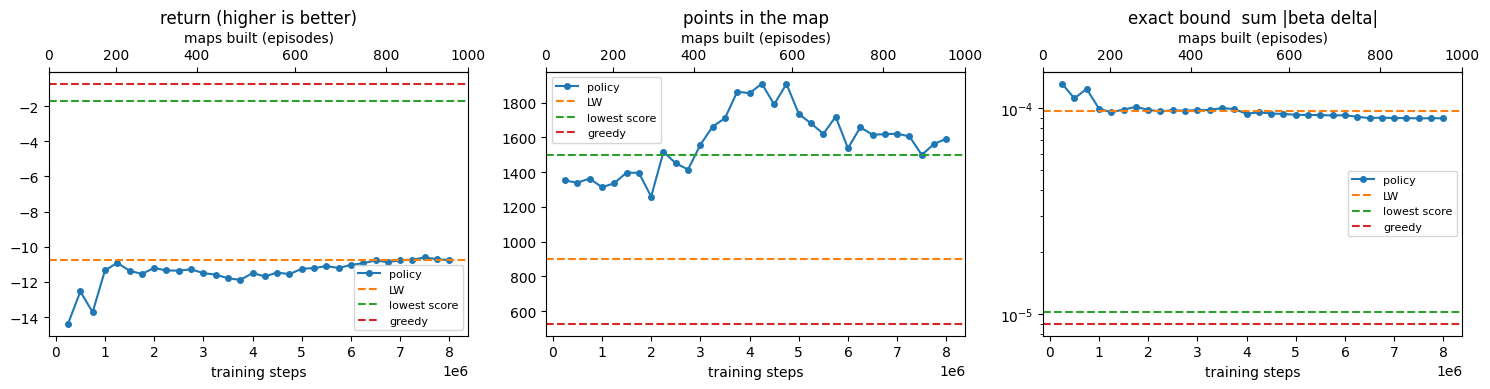

34 frames: map_000000012.png ... map_final.png
saved: runs10-14\inflow_smooth_scratch_z50-30_lam1-1\images\training_progress.mp4
120 frames, 1619 points | saved: runs10-14\inflow_smooth_scratch_z50-30_lam1-1\images\build_final.mp4
120 frames, 900 points | saved: runs10-14\inflow_smooth_scratch_z50-30_lam1-1\images\build_LW.mp4


'runs10-14\\inflow_smooth_scratch_z50-30_lam1-1\\images\\build_LW.mp4'

In [ ]:
# ── Learning curves and videos of the finished run (no training here) ──
from map_progress_video import make_progress_video
from map_build_video import make_build_video
from learning_curves import plot_learning_curves

model = MaskablePPO.load(os.path.join(ckpt_dir, "ppo_final"))        # or set run_dir / ckpt_dir to a copied run folder

def baseline(rule):
    """Return (same reward as the agent, at LAM_PLOT), points and exact bound of a fixed rule's map."""
    mm = build_map(Z_TRAIN, rule)
    rep = report(mm)
    return {"return": -score_sum(mm) / EPS - LAM_PLOT * (rep["points"] - 1) / n_lw(Z_TRAIN),
            "points": rep["points"], "bound": rep["bound"]}

baselines = {"LW": baseline(lw), "lowest score": baseline(lowest_score), "greedy": baseline(greedy_rule(LAM_PLOT))}
for name, b in baselines.items():
    print(f"{name:12s}: return {b['return']:.2f}, {b['points']} points, bound {b['bound']:.1e}")
env = run_policy(model, Z_TRAIN, LAM_PLOT)
rep = report(env.m)
print(f"{'agent':12s}: return {env.ret:.2f}, {rep['points']} points, bound {rep['bound']:.1e}, error {rep['error']:.1e}")

plot_learning_curves(os.path.join(run_dir, "snapshots.json"), baselines, skip=1)   # skip=1: leave out the untrained policy
make_progress_video(img_dir, fps=2)
make_build_video(env.m, os.path.join(img_dir, "build_final.mp4"), is_known, title="trained policy")
make_build_video(build_map(Z_TRAIN, lw), os.path.join(img_dir, "build_LW.mp4"), is_known, title="Lax-Wendroff")

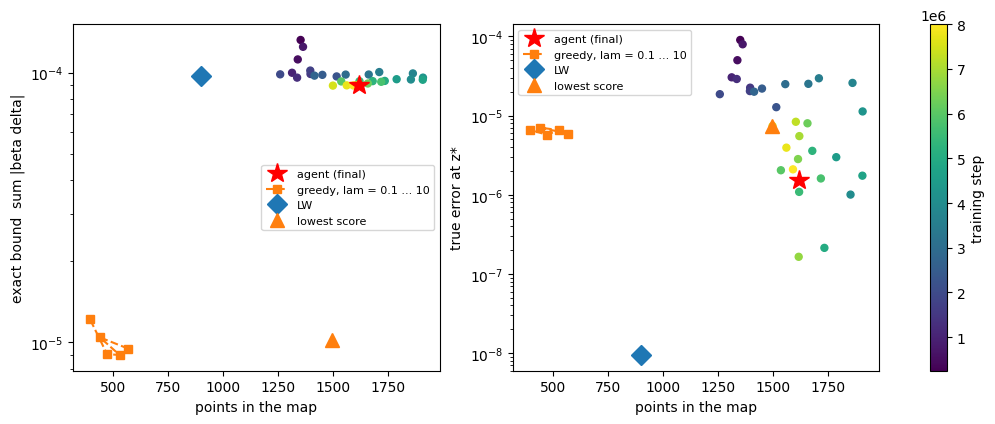

In [ ]:
# ── Points vs error: the agent over training, the rules, and greedy over lam ──
with open(os.path.join(run_dir, "snapshots.json")) as f:
    hist = json.load(f)[1:]                                            # skip the untrained policy
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for ax, key, label in [(axes[0], "bound", "exact bound  sum |beta delta|"), (axes[1], "error", "true error at z*")]:
    sc = ax.scatter([h["points"] for h in hist], [h[key] for h in hist], c=[h["step"] for h in hist], cmap="viridis", s=25)
    ax.plot(rep["points"], rep[key], "r*", ms=15, label="agent (final)")
    g = [report(build_map(Z_TRAIN, greedy_rule(lam))) for lam in [0.1, 0.3, 1, 3, 10]]
    ax.plot([r["points"] for r in g], [r[key] for r in g], "s--", color="C1", label="greedy, lam = 0.1 ... 10")
    for name, rule, mk in [("LW", lw, "D"), ("lowest score", lowest_score, "^")]:
        r = report(build_map(Z_TRAIN, rule))
        ax.plot(r["points"], r[key], mk, ms=10, label=name)
    ax.set_yscale("log"); ax.set_xlabel("points in the map"); ax.set_ylabel(label); ax.legend(fontsize=8)
fig.colorbar(sc, ax=axes, label="training step")
plt.show()